In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, random_split
from torchvision import transforms
from PIL import Image
import os
import numpy as np
from tqdm import tqdm
from sklearn.metrics import roc_auc_score, roc_curve
import zipfile
from torch.amp import autocast, GradScaler
from pytorch_msssim import ssim, ms_ssim, SSIM, MS_SSIM
from torch.optim.lr_scheduler import OneCycleLR
import matplotlib.pyplot as plt

In [2]:
torch.backends.cudnn.benchmark = True
torch.cuda.empty_cache()
os.environ['PYTORCH_CUDA_ALLOC_CONF'] = 'expandable_segments:True'

In [3]:
print("Is CUDA available?", torch.cuda.is_available())
print("CUDA device name:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "No GPU found")
print("CUDA version:", torch.version.cuda)
print("Number of CUDA devices:", torch.cuda.device_count())
print("Current device:", torch.cuda.current_device())

Is CUDA available? True
CUDA device name: NVIDIA GeForce RTX 4050 Laptop GPU
CUDA version: 12.4
Number of CUDA devices: 1
Current device: 0


In [3]:
class UCSDDataset(Dataset):
    def __init__(self, root_dir, sequence_length=8, transform=None, mode='train'):
        self.root_dir = root_dir
        self.transform = transform
        self.sequence_length = sequence_length
        self.mode = mode
        self.frame_sequences = []
        self.labels = []
        self.load_sequences()

    def load_sequences(self):
        if self.mode == 'train':
            print(f"Loading sequences from: {self.root_dir}")
            # Load only normal sequences for training
            normal_path = os.path.join(self.root_dir, 'Normal')
            for folder in os.listdir(normal_path):
                folder_path = os.path.join(normal_path, folder)
                if os.path.isdir(folder_path):
                    frames = []
                    for frame_name in sorted(os.listdir(folder_path)):
                        if frame_name.endswith('.tif'):
                            frames.append(os.path.join(folder_path, frame_name))
                    # Create sequences of frames
                    for i in range(0, len(frames) - self.sequence_length + 1):
                        self.frame_sequences.append(frames[i:i + self.sequence_length])
                        self.labels.append(0)  # Normal sequences labeled as 0
        else:
            # Load both normal and anomaly sequences for testing
            normal_path = os.path.join(self.root_dir, 'Normal')
            anomaly_path = os.path.join(self.root_dir, 'Anomaly')
            for folder in os.listdir(normal_path):
                folder_path = os.path.join(normal_path, folder)
                if os.path.isdir(folder_path):
                    frames = []
                    for frame_name in sorted(os.listdir(folder_path)):
                        if frame_name.endswith('.tif'):
                            frames.append(os.path.join(folder_path, frame_name))
                    # Create sequences of frames
                    for i in range(0, len(frames) - self.sequence_length + 1):
                        self.frame_sequences.append(frames[i:i + self.sequence_length])
                        self.labels.append(0)  # Normal sequences labeled as 0
            for folder in os.listdir(anomaly_path):
                folder_path = os.path.join(anomaly_path, folder)
                if os.path.isdir(folder_path):
                    frames = []
                    for frame_name in sorted(os.listdir(folder_path)):
                        if frame_name.endswith('.tif'):
                            frames.append(os.path.join(folder_path, frame_name))
                    # Create sequences of frames
                    for i in range(0, len(frames) - self.sequence_length + 1):
                        self.frame_sequences.append(frames[i:i + self.sequence_length])
                        self.labels.append(1)  # Anomaly sequences labeled as 1

        print(f"Loaded {len(self.frame_sequences)} sequences from {self.root_dir}")

    def __len__(self):
        return len(self.frame_sequences)

    def __getitem__(self, idx):
        max_retries = 3  # Limit number of retries
        current_idx = idx
        
        for _ in range(max_retries):
            frame_sequence = []
            try:
                for frame_path in self.frame_sequences[current_idx]:
                    image = Image.open(frame_path).convert("RGB")
                    if self.transform:
                        image = self.transform(image)
                    frame_sequence.append(image)
                return torch.stack(frame_sequence), self.labels[idx]
            except (OSError, IOError) as e:
                print(f"Error loading image at index {current_idx}: {e}")
                current_idx = (current_idx + 1) % len(self)
        
        raise RuntimeError(f"Failed to load valid sequence after {max_retries} attempts")

In [4]:
class ConvLSTMCell(nn.Module):
    def __init__(self, input_channels, hidden_channels, kernel_size):
        super(ConvLSTMCell, self).__init__()
        self.input_channels = input_channels
        self.hidden_channels = hidden_channels
        self.kernel_size = kernel_size
        self.padding = kernel_size // 2
        total_channels = input_channels + hidden_channels

        self.conv = nn.Conv2d(
        total_channels,  # Should be input_channels + hidden_channels
        4 * hidden_channels,  # Four gates for LSTM
        kernel_size=kernel_size,
        padding=kernel_size // 2
    )
        
        # Initialize weights using Xavier/Glorot initialization
        nn.init.xavier_uniform_(self.conv.weight)
        nn.init.zeros_(self.conv.bias)

    def forward(self, input_tensor, cur_state):
        h_cur, c_cur = cur_state
        
        combined = torch.cat([input_tensor, h_cur], dim=1)
        conv_output = self.conv(combined)
        
        # Split gates
        cc_i, cc_f, cc_o, cc_g = torch.split(conv_output, self.hidden_channels, dim=1)
        
        i = torch.sigmoid(cc_i)
        f = torch.sigmoid(cc_f)
        o = torch.sigmoid(cc_o)
        g = torch.tanh(cc_g)
        
        c_next = f * c_cur + i * g
        h_next = o * torch.tanh(c_next)
        
        return h_next, c_next

In [5]:
class TemporalAttention(nn.Module):
    def __init__(self, hidden_channels):
        super().__init__()
        self.attention = nn.Sequential(
            nn.Conv2d(hidden_channels, hidden_channels // 2, kernel_size=1),
            nn.ReLU(),
            nn.Conv2d(hidden_channels // 2, 1, kernel_size=1),
            nn.Sigmoid()
        )
    
    def forward(self, x):
        attention_weights = self.attention(x)
        return x * attention_weights

class SpatialAttention(nn.Module):
    def __init__(self, hidden_channels):
        super().__init__()
        self.attention = nn.Sequential(
            nn.Conv2d(hidden_channels * 2, hidden_channels, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(hidden_channels, 1, kernel_size=1),
            nn.Sigmoid()
        )
    
    def forward(self, x, context):
        combined = torch.cat([x, context], dim=1)
        attention_weights = self.attention(combined)
        return x * attention_weights

In [6]:
class Encoder(nn.Module):
    def __init__(self, input_channels, hidden_channels):
        super(Encoder, self).__init__()
        
        self.conv1 = nn.Sequential(
            nn.Conv2d(input_channels, hidden_channels[0], kernel_size=3, padding=1),
            nn.BatchNorm2d(hidden_channels[0]),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )
        
        self.conv2 = nn.Sequential(
            nn.Conv2d(hidden_channels[0], hidden_channels[1], kernel_size=3, padding=1),
            nn.BatchNorm2d(hidden_channels[1]),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )
        
        self.convlstm = ConvLSTMCell(hidden_channels[1], hidden_channels[2], kernel_size=3)
        self.temporal_attention = TemporalAttention(hidden_channels[2])
        self.hidden_channels = hidden_channels

    def init_hidden(self, batch_size, height, width):
        device = next(self.parameters()).device
        return (
            torch.zeros(batch_size, self.hidden_channels[2], height//4, width//4, device=device),
            torch.zeros(batch_size, self.hidden_channels[2], height//4, width//4, device=device)
        )

    def forward(self, x):
        # x shape: (batch, seq_len, channels, height, width)
        batch_size, seq_len, channels, height, width = x.size()
        h_t, c_t = self.init_hidden(batch_size, height, width)
        
        encoder_states = []
        
        for t in range(seq_len):
            # Extract current timestep: (batch, channels, height, width)
            x_t = x[:, t, :, :, :]
            
            # Apply CNN layers
            conv1_out = self.conv1(x_t)  # Now receives correct 4D input
            conv2_out = self.conv2(conv1_out)
            
            # Apply ConvLSTM
            h_t, c_t = self.convlstm(conv2_out, (h_t, c_t))
            
            # Apply temporal attention
            h_t_attended = self.temporal_attention(h_t)
            
            encoder_states.append((conv1_out, conv2_out, h_t_attended))
        
        return h_t_attended, c_t, encoder_states

In [7]:
class Decoder(nn.Module):
    def __init__(self, hidden_channels):
        super(Decoder, self).__init__()
        
        self.convlstm = ConvLSTMCell(
            input_channels=hidden_channels[-1],  # 256
            hidden_channels=hidden_channels[-1],  # Should match input_channels
            kernel_size=3
        )
        self.spatial_attention = SpatialAttention(hidden_channels[-1])
        
        # First deconv: 256 -> 128
        self.deconv1 = nn.Sequential(
            nn.ConvTranspose2d(hidden_channels[-1], hidden_channels[-2], kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(hidden_channels[-2]),
            nn.ReLU()
        )
        
        # Crucial change: Account for skip connection in input channels
        # Input: 128 (from deconv1) + 64 (from skip) = 192
        self.deconv2 = nn.Sequential(
            nn.ConvTranspose2d(hidden_channels[-2] + hidden_channels[-3], 3, kernel_size=4, stride=2, padding=1),
            nn.Tanh()
        )

    def forward(self, h_t, c_t, encoder_states, seq_len):
        # Apply spatial attention
        context = encoder_states[-1][2]  # Assuming context is from encoder
        h_t = self.spatial_attention(h_t, context)
        
        # Generate reconstructed frames
        reconstructed_frames = []
        for t in range(seq_len):
            h_t, c_t = self.convlstm(h_t, (h_t, c_t))
            # Upsample and generate frame
            frame = self.deconv1(h_t)
            frame = self.deconv2(torch.cat([frame, encoder_states[t][0]], dim=1))
            reconstructed_frames.append(frame)
        
        return torch.stack(reconstructed_frames, dim=1), h_t, c_t

In [8]:
class Discriminator(nn.Module):
    def __init__(self, input_channels):
        super(Discriminator, self).__init__()
        
        def discriminator_block(in_channels, out_channels, normalize=True):
            layers = [nn.Conv2d(in_channels, out_channels, kernel_size=4, stride=2, padding=1)]
            if normalize:
                layers.append(nn.BatchNorm2d(out_channels))
            layers.append(nn.LeakyReLU(0.2))
            return layers
        
        self.model = nn.Sequential(
            *discriminator_block(input_channels, 64, normalize=False),
            *discriminator_block(64, 128),
            *discriminator_block(128, 256),
            *discriminator_block(256, 512),
            nn.Conv2d(512, 1, kernel_size=4, stride=1, padding=0)
        )

    def forward(self, x):
        return torch.sigmoid(self.model(x))

In [9]:
class FeatureMatchingLoss(nn.Module):
    def __init__(self):
        super().__init__()
        self.l1_loss = nn.L1Loss()
    
    def forward(self, real_features, fake_features):
        return sum(self.l1_loss(rf, ff) for rf, ff in zip(real_features, fake_features))

class PerceptualLoss(nn.Module):
    def __init__(self):
        super().__init__()
        # Using pre-trained VGG features
        vgg = torchvision.models.vgg16(pretrained=True).features
        self.blocks = nn.ModuleList([
            vgg[:4],  # First block
            vgg[4:9],  # Second block
            vgg[9:16]  # Third block
        ])
        for block in self.blocks:
            for param in block.parameters():
                param.requires_grad = False
    
    def forward(self, x, y):
        loss = 0
        for block in self.blocks:
            x = block(x)
            y = block(y)
            loss += F.mse_loss(x, y)
        return loss

class CombinedLoss(nn.Module):
    def __init__(self, alpha=0.7, beta=0.15, gamma=0.15):
        super().__init__()
        self.alpha = alpha
        self.beta = beta
        self.gamma = gamma
        self.reconstruction_loss = nn.MSELoss()
        self.perceptual_loss = PerceptualLoss()
        self.feature_matching_loss = FeatureMatchingLoss()
    
    def forward(self, pred, target, pred_features=None, target_features=None):
        rec_loss = self.reconstruction_loss(pred, target)
        perc_loss = self.perceptual_loss(pred, target)
        feat_loss = (self.feature_matching_loss(pred_features, target_features) 
                    if pred_features is not None and target_features is not None 
                    else 0)
        
        return (self.alpha * rec_loss + 
                self.beta * perc_loss + 
                self.gamma * feat_loss)

In [10]:
class ConvLSTMAutoencoder(nn.Module):
    def __init__(self, input_channels=3, hidden_channels=[32, 64, 128], dropout_prob=0.2):
        super().__init__()
        print(f"Initializing with hidden channels: {hidden_channels}")
        
        self.encoder = Encoder(input_channels, hidden_channels)
        self.decoder = Decoder(hidden_channels)
        self.dropout = nn.Dropout(p=dropout_prob)

        # Print model structure
        def count_parameters(model):
            return sum(p.numel() for p in model.parameters() if p.requires_grad)
        print(f"Total trainable parameters: {count_parameters(self)}")
    
    def forward(self, x):
        batch_size, seq_len, _, height, width = x.size()
        
        # Encoder
        h_t, c_t, encoder_states = self.encoder(x)
        
        # Apply dropout
        h_t = self.dropout(h_t)
        
        # Decoder
        reconstructed_frames, h_t, c_t = self.decoder(h_t, c_t, encoder_states, seq_len)
        
        return reconstructed_frames

In [11]:
# Define transforms
transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ColorJitter(brightness=0.1, contrast=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Create datasets
sequence_length = 8  # Number of frames in each sequence

# Set random seed for reproducibility
torch.manual_seed(42)

# Create training dataset
train_dataset = UCSDDataset(
    'UCSD_Anomaly_Dataset/UCSDped1/Train',
    sequence_length=sequence_length,
    transform=transform,
    mode='train'
)

# Split training dataset into training and validation sets
train_size = int(0.8 * len(train_dataset))
val_size = len(train_dataset) - train_size
train_dataset, val_dataset = random_split(train_dataset, [train_size, val_size])

# Create test dataset
test_dataset = UCSDDataset(
    'UCSD_Anomaly_Dataset/UCSDped1/Test',
    sequence_length=sequence_length,
    transform=transform,
    mode='test'
)

# Create dataloaders
train_loader = DataLoader(
    train_dataset,
    batch_size=4,
    shuffle=True,
    num_workers=0,
    pin_memory=True,
    # prefetch_factor=2,
    # persistent_workers=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print(f"Dataset size: {len(train_dataset)}")
print(f"First item shape: {next(iter(train_loader))[0].shape}")

Loading sequences from: UCSD_Anomaly_Dataset/UCSDped1/Train
Loaded 4253 sequences from UCSD_Anomaly_Dataset/UCSDped1/Train
Loaded 5800 sequences from UCSD_Anomaly_Dataset/UCSDped1/Test
Dataset size: 3402
First item shape: torch.Size([4, 8, 3, 128, 128])


In [12]:
# Initialize model and training components
class CombinedLoss(nn.Module):
    def __init__(self, alpha=0.7, beta=0.15):
        super().__init__()
        self.alpha = alpha
        self.beta = beta
        self.mse = nn.MSELoss()
        self.ssim = SSIM()
        self.l1 = nn.L1Loss()
    
    def forward(self, pred, target):
        # pred and target are 5D tensors: [batch_size, sequence_length, channels, height, width]
        batch_size, sequence_length, channels, height, width = pred.shape
        
        # Reshape to merge batch and sequence dimensions
        pred_reshaped = pred.view(-1, channels, height, width)  # [batch_size * sequence_length, channels, height, width]
        target_reshaped = target.view(-1, channels, height, width)  # [batch_size * sequence_length, channels, height, width]
        
        # Compute MSE loss
        mse_loss = self.mse(pred_reshaped, target_reshaped)
        
        # Compute SSIM loss
        ssim_loss = 1 - self.ssim(pred_reshaped, target_reshaped)
        
        # Compute L1 loss
        l1_loss = self.l1(pred_reshaped, target_reshaped)
        
        # Combine losses
        return self.alpha * mse_loss + (1 - self.alpha - self.beta) * ssim_loss + self.beta * l1_loss

class GANLoss(nn.Module):
    def __init__(self):
        super(GANLoss, self).__init__()
        self.bce_loss = nn.BCELoss()
        self.mse_loss = nn.MSELoss()

    def generator_loss(self, reconstructed_frames, real_frames, discriminator_output):
        adversarial_loss = self.bce_loss(discriminator_output, torch.ones_like(discriminator_output))
        reconstruction_loss = self.mse_loss(reconstructed_frames, real_frames)
        return adversarial_loss + reconstruction_loss

    def discriminator_loss(self, real_output, fake_output):
        real_labels = torch.ones_like(real_output)
        fake_labels = torch.zeros_like(fake_output)
        real_loss = disc_criterion(real_output, real_labels)
        fake_loss = disc_criterion(fake_output, fake_labels)
        return (real_loss + fake_loss) / 2

In [13]:
epochs = 30
best_loss = float('inf')
patience = 10
trigger_times = 0
save_dir = './saved_models'
os.makedirs(save_dir, exist_ok=True)

def save_model(model, optimizer, epoch, loss, path):
    torch.save({
        'model_state_dict': model.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'epoch': epoch,
        'loss': loss,
    }, path)

sequence_lengths = [4, 6, 8]
scaler = GradScaler('cuda')
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = ConvLSTMAutoencoder(input_channels=3, hidden_channels=[16, 32, 64], dropout_prob=0.2)

# Then apply weight initialization
def init_weights(m):
    if isinstance(m, nn.Conv2d):
        nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
    elif isinstance(m, nn.BatchNorm2d):
        nn.init.constant_(m.weight, 1)
        nn.init.constant_(m.bias, 0)

model.apply(init_weights)

# Then move to device
model = model.to(device)
criterion = CombinedLoss().to(device)
optimizer = optim.Adam(model.parameters(), lr=0.0001)
scheduler = OneCycleLR(
    optimizer,
    max_lr=0.001,
    epochs=epochs,
    steps_per_epoch=len(train_loader),
    pct_start=0.3,
    div_factor=25
)

torch.backends.cudnn.benchmark = True

Initializing with hidden channels: [16, 32, 64]
Total trainable parameters: 632933


C:\Users\mayan\AppData\Local\Programs\Python\Python312\Lib\site-packages\torch\nn\modules\module.py:1160: UserWarning: expandable_segments not supported on this platform (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\builder\windows\pytorch\c10/cuda/CUDAAllocatorConfig.h:28.)
  return t.to(


In [14]:
def train_epoch(model, discriminator, train_loader, gen_criterion, disc_criterion, 
                optimizer, d_optimizer, scheduler, scaler, device):
    model.train()
    discriminator.train()
    total_gen_loss = 0
    total_disc_loss = 0

    print("Starting training epoch...")
    
    pbar = tqdm(train_loader)
    for batch_idx, batch_data in enumerate(pbar):
        try:
            sequences, labels = batch_data
            print(f"Batch {batch_idx}: sequences shape: {sequences.shape}, labels shape: {labels.shape}")
            
            sequences = sequences.to(device)
            labels = labels.to(device)
            batch_size = sequences.size(0)
    
            # Train Generator
            optimizer.zero_grad()
            with torch.amp.autocast(device_type='cuda'):
                reconstructed = model(sequences)
                
                # Reshape reconstructed and sequences for the Discriminator
                reconstructed_reshaped = reconstructed.view(-1, *reconstructed.shape[2:])  # [batch_size * sequence_length, channels, height, width]
                sequences_reshaped = sequences.view(-1, *sequences.shape[2:])  # [batch_size * sequence_length, channels, height, width]
                
                fake_features = discriminator(reconstructed_reshaped)
                real_features = discriminator(sequences_reshaped)
                
                # Only pass reconstructed and sequences to the gen_criterion
                gen_loss = gen_criterion(reconstructed, sequences)
            
            scaler.scale(gen_loss).backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            scaler.step(optimizer)
            
            # Train Discriminator
            d_optimizer.zero_grad()
            with torch.amp.autocast(device_type='cuda'):
                real_output = discriminator(sequences_reshaped)
                fake_output = discriminator(reconstructed_reshaped.detach())
                
                # Compute discriminator loss using BCEWithLogitsLoss
                real_labels = torch.ones_like(real_output)
                fake_labels = torch.zeros_like(fake_output)
                
                real_loss = disc_criterion(real_output, real_labels)
                fake_loss = disc_criterion(fake_output, fake_labels)
                disc_loss = (real_loss + fake_loss) / 2
            
            scaler.scale(disc_loss).backward()
            torch.nn.utils.clip_grad_norm_(discriminator.parameters(), max_norm=1.0)
            scaler.step(d_optimizer)
            
            scaler.update()
            
            total_gen_loss += gen_loss.item() * batch_size
            total_disc_loss += disc_loss.item() * batch_size
            
            pbar.set_description(f"Gen Loss: {gen_loss.item():.4f}, Disc Loss: {disc_loss.item():.4f}")

        except Exception as e:
            print(f"Error in batch {batch_idx}: {str(e)}")
            print(f"Batch data type: {type(batch_data)}")
            print(f"Batch data structure: {batch_data[0].shape if isinstance(batch_data, tuple) else None}")
            raise e
    
    scheduler.step()
    
    return total_gen_loss / len(train_loader.dataset), total_disc_loss / len(train_loader.dataset)

In [15]:
def validate(model, val_loader, criterion, device):
    model.eval()
    total_loss = 0
    
    with torch.no_grad():
        for batch in val_loader:
            # Proper unpacking
            sequences, labels = batch  # Unpack the tuple
            sequences = sequences.to(device)
            reconstructed = model(sequences)
            loss = criterion(reconstructed, sequences)
            total_loss += loss.item() * sequences.size(0)
    
    return total_loss / len(val_loader.dataset)

In [16]:
def train(model, discriminator, train_loader, val_loader, gen_criterion, disc_criterion,
          optimizer, d_optimizer, scheduler, scaler, device, epochs, save_dir):
    best_val_loss = float('inf')
    patience = 10
    patience_counter = 0
    
    for epoch in range(epochs):
        # Train
        train_gen_loss, train_disc_loss = train_epoch(
            model, discriminator, train_loader, gen_criterion, disc_criterion,
            optimizer, d_optimizer, scheduler, scaler, device
            
        )
        
        # Validate
        val_loss = validate(model, val_loader, gen_criterion, device)
        
        print(f"Epoch {epoch+1}/{epochs}")
        print(f"Train Gen Loss: {train_gen_loss:.4f}, Train Disc Loss: {train_disc_loss:.4f}")
        print(f"Val Loss: {val_loss:.4f}")
        
        # Save best model
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            patience_counter = 0
            torch.save({
                'model_state_dict': model.state_dict(),
                'discriminator_state_dict': discriminator.state_dict(),
                'optimizer_state_dict': optimizer.state_dict(),
                'd_optimizer_state_dict': d_optimizer.state_dict(),
                'epoch': epoch,
                'best_val_loss': best_val_loss
            }, os.path.join(save_dir, 'best_model.pth'))
        else:
            patience_counter += 1
            if patience_counter >= patience:
                print("Early stopping triggered!")
                break

In [20]:
def evaluate(model, test_loader, device):
    model.eval()
    all_reconstruction_errors = []
    all_labels = []
    
    with torch.no_grad():
        for sequences, labels in test_loader:
            sequences = sequences.to(device)
            reconstructed = model(sequences)
            
            # Calculate reconstruction error for each sequence
            error = F.mse_loss(reconstructed, sequences, reduction='none')
            
            # Average over all dimensions except batch: channels, height, width, and sequence length
            # This gives us one score per sequence
            error = error.mean(dim=[1, 2, 3, 4])  # Now we get a single value per sequence
            
            all_reconstruction_errors.append(error.cpu().numpy())
            all_labels.append(labels.numpy())
    
    # Concatenate all errors and labels
    all_reconstruction_errors = np.concatenate(all_reconstruction_errors)
    all_labels = np.concatenate(all_labels)
    
    # Calculate ROC and AUC
    fpr, tpr, thresholds = roc_curve(all_labels, all_reconstruction_errors)
    auc_score = roc_auc_score(all_labels, all_reconstruction_errors)
    
    # Calculate EER
    fnr = 1 - tpr
    eer_threshold = thresholds[np.nanargmin(np.absolute(fnr - fpr))]
    eer = fpr[np.nanargmin(np.absolute(fnr - fpr))]
    
    return {
        'auc_score': auc_score,
        'eer': eer,
        'fpr': fpr,
        'tpr': tpr,
        'thresholds': thresholds
    }

In [18]:
# Add this right after dataset creation
sample_batch = next(iter(train_loader))
print(f"Sample batch type: {type(sample_batch)}")
print(f"Sample batch structure: {[x.shape if torch.is_tensor(x) else type(x) for x in sample_batch]}")

Sample batch type: <class 'list'>
Sample batch structure: [torch.Size([4, 8, 3, 128, 128]), torch.Size([4])]


In [31]:
def inspect_model(model):
    print("=== Model Architecture Analysis ===")
    
    # Method 1: Basic parameter counting
    total_params = sum(p.numel() for p in model.parameters())
    trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    
    print(f"\nParameter Analysis:")
    print(f"Total parameters: {total_params:,}")
    print(f"Trainable parameters: {trainable_params:,}")
    
    # Method 2: Layer inspection
    print("\nLayer Structure:")
    for name, module in model.named_children():
        params = sum(p.numel() for p in module.parameters())
        print(f"{name}: {module.__class__.__name__} ({params:,} parameters)")
        
    # Method 3: Memory estimation
    total_memory = 0
    for param in model.parameters():
        total_memory += param.numel() * param.element_size()
    print(f"\nApproximate model size: {total_memory / 1024 / 1024:.2f} MB")
    
    # Method 4: Device location check
    devices = set(param.device for param in model.parameters())
    print(f"\nModel device distribution: {devices}")

try:
    inspect_model(model)
except Exception as e:
    print(f"Inspection failed: {str(e)}")

=== Model Architecture Analysis ===

Parameter Analysis:
Total parameters: 632,933
Trainable parameters: 632,933

Layer Structure:
encoder: Encoder (228,737 parameters)
decoder: Decoder (404,196 parameters)
dropout: Dropout (0 parameters)

Approximate model size: 2.41 MB

Model device distribution: {device(type='cuda', index=0)}


In [32]:
def trace_model_shapes(model):
    print("\n=== Shape Transformation Analysis ===")
    
    # Create dummy input
    batch_size = 2
    seq_len = 8
    channels = 3
    height = width = 128
    
    try:
        dummy_input = torch.randn(batch_size, seq_len, channels, height, width).to(next(model.parameters()).device)
        print(f"Input shape: {dummy_input.shape}")
        
        # Register forward hook
        shapes = []
        def hook(module, input, output):
            shapes.append({
                'module': module.__class__.__name__,
                'input_shape': str([tuple(x.shape) for x in input]),
                'output_shape': str(output.shape) if isinstance(output, torch.Tensor) else str(output)
            })
        
        hooks = []
        for name, module in model.named_modules():
            hooks.append(module.register_forward_hook(hook))
        
        # Forward pass
        with torch.no_grad():
            _ = model(dummy_input)
            
        # Remove hooks
        for h in hooks:
            h.remove()
            
        # Print shape transformations
        for s in shapes:
            print(f"\n{s['module']}:")
            print(f"  Input: {s['input_shape']}")
            print(f"  Output: {s['output_shape']}")
            
    except Exception as e:
        print(f"Shape analysis failed: {str(e)}")

In [33]:
def analyze_model_architecture(model):
    print("=== Comprehensive Model Analysis ===")
    
    inspect_model(model)
    trace_model_shapes(model)
    
    # Additional architecture insights
    print("\nArchitectural Overview:")
    def recurse_modules(module, depth=0):
        prefix = "  " * depth
        for name, child in module.named_children():
            print(f"{prefix}{name}: {child.__class__.__name__}")
            recurse_modules(child, depth + 1)
    
    recurse_modules(model)

In [ ]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Model parameters
input_channels = 3
hidden_channels = [64, 128, 256]
sequence_length = 8
batch_size = 16
epochs = 30
learning_rate = 1e-4

# Initialize models
model = ConvLSTMAutoencoder(
    input_channels=input_channels,
    hidden_channels=hidden_channels,
    dropout_prob=0.2
).to(device)

discriminator = Discriminator(input_channels=input_channels).to(device)

# Initialize optimizers
optimizer = optim.Adam(model.parameters(), lr=learning_rate)
d_optimizer = optim.Adam(discriminator.parameters(), lr=learning_rate)

# Initialize scheduler
scheduler = OneCycleLR(
    optimizer,
    max_lr=learning_rate*10,
    epochs=epochs,
    steps_per_epoch=len(train_loader),
    pct_start=0.3
)

# Initialize loss functions
gen_criterion = CombinedLoss().to(device)
disc_criterion = nn.BCEWithLogitsLoss().to(device)

# Initialize GradScaler for mixed precision training
scaler = GradScaler()

model = model.to(device)
discriminator = discriminator.to(device)
gen_criterion = gen_criterion.to(device)
disc_criterion = disc_criterion.to(device)

# Create save directory
save_dir = 'saved_models'
os.makedirs(save_dir, exist_ok=True)

# Train the model
train(
    model=model,
    discriminator=discriminator,
    train_loader=train_loader,
    val_loader=val_loader,
    gen_criterion=gen_criterion,
    disc_criterion=disc_criterion,
    optimizer=optimizer,
    d_optimizer=d_optimizer,
    scheduler=scheduler,
    scaler=scaler,
    device=device,
    epochs=epochs,
    save_dir=save_dir
)

Using device: cuda
Initializing with hidden channels: [64, 128, 256]
Total trainable parameters: 10082693


C:\Users\mayan\AppData\Local\Temp\ipykernel_16884\3746984615.py:14: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load('saved_models/best_model.pth', map_

Model loaded successfully

Evaluation Results:
AUC Score: 0.5780
EER: 0.4544


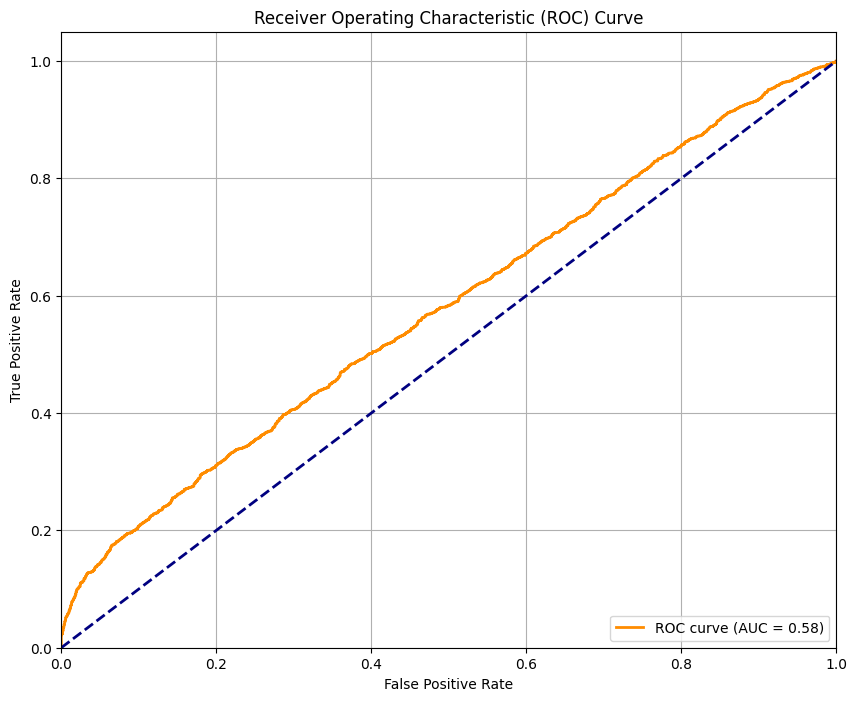

ValueError: x must have 2 or fewer dimensions

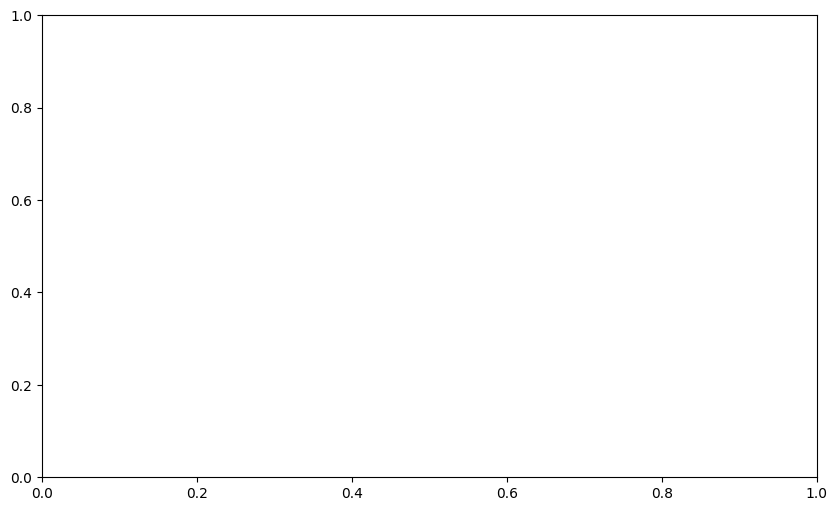

In [21]:
def load_and_evaluate():
    # Set device
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    print(f"Using device: {device}")

    # Initialize model architecture (without training)
    model = ConvLSTMAutoencoder(
        input_channels=3,
        hidden_channels=[64, 128, 256],
        dropout_prob=0.2
    ).to(device)

    # Load the trained weights
    checkpoint = torch.load('saved_models/best_model.pth', map_location=device)
    model.load_state_dict(checkpoint['model_state_dict'])
    print("Model loaded successfully")

    # Set model to evaluation mode
    model.eval()

    # Evaluate
    results = evaluate(model, test_loader, device)
    
    # Print metrics
    print(f"\nEvaluation Results:")
    print(f"AUC Score: {results['auc_score']:.4f}")
    print(f"EER: {results['eer']:.4f}")

    # Plot ROC curve
    plt.figure(figsize=(10, 8))
    plt.plot(results['fpr'], results['tpr'], color='darkorange', lw=2, 
             label=f'ROC curve (AUC = {results["auc_score"]:.2f})')
    plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Receiver Operating Characteristic (ROC) Curve')
    plt.legend(loc="lower right")
    plt.grid(True)
    plt.savefig('roc_curve.png')
    plt.show()

    # Optional: Plot error distribution
    def plot_error_distribution(error_scores, labels):
        plt.figure(figsize=(10, 6))
        plt.hist([error_scores[labels == 0], error_scores[labels == 1]], 
                label=['Normal', 'Anomaly'], bins=50, density=True)
        plt.xlabel('Reconstruction Error')
        plt.ylabel('Density')
        plt.title('Distribution of Reconstruction Errors')
        plt.legend()
        plt.grid(True)
        plt.savefig('error_distribution.png')
        plt.show()

    # Modified evaluate function to return error scores and labels
    def get_error_distribution(model, test_loader, device):
        model.eval()
        all_errors = []
        all_labels = []
        
        with torch.no_grad():
            for sequences, labels in test_loader:
                sequences = sequences.to(device)
                reconstructed = model(sequences)
                error = torch.mean((reconstructed - sequences) ** 2, dim=(2, 3, 4))
                all_errors.append(error.cpu().numpy())
                all_labels.append(labels.numpy())
        
        return np.concatenate(all_errors), np.concatenate(all_labels)

    # Plot error distribution
    errors, labels = get_error_distribution(model, test_loader, device)
    plot_error_distribution(errors, labels)

if __name__ == '__main__':
    load_and_evaluate()